In [1]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
path = "ADP.2025-07-06T07_52_11.876.fits"

with fits.open(path) as hdul:
    hdul.info()
    for i, hdu in enumerate(hdul):
        print(i, hdu.name, hdu.data.shape if hdu.data is not None else None)

Filename: ADP.2025-07-06T07_52_11.876.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      34   ()      
  1  ID            1 ImageHDU        32   (6080, 1733)   float32   
  2  FLUX          1 ImageHDU        32   (6080, 1733)   float32   
  3  SNR           1 ImageHDU        32   (6080, 1733)   float32   
  4  SNRBIN        1 ImageHDU        32   (6080, 1733)   float32   
  5  BIN_ID        1 ImageHDU        32   (6080, 1733)   float32   
  6  V_STARS       1 ImageHDU        32   (6080, 1733)   float32   
  7  FORM_ERR_V_STARS    1 ImageHDU        32   (6080, 1733)   float32   
  8  SIGMA_STARS    1 ImageHDU        32   (6080, 1733)   float32   
  9  FORM_ERR_SIGMA_STARS    1 ImageHDU        32   (6080, 1733)   float32   
 10  H3_STARS      1 ImageHDU        32   (6080, 1733)   float32   
 11  FORM_ERR_H3_STARS    1 ImageHDU        32   (6080, 1733)   float32   
 12  H4_STARS      1 ImageHDU        32   (6080, 1733)   float32   
 13 

In [3]:
with fits.open(path) as hdul:
    ha = hdul["HA6562_FLUX"].data
    hb = hdul["HB4861_FLUX"].data
    oiii = hdul["OIII5006_FLUX"].data
    nii = hdul["NII6583_FLUX"].data
    sii6717 = hdul["SII6716_FLUX"].data
    sii6731 = hdul["SII6730_FLUX"].data

    ha_err = hdul["HA6562_FLUX_ERR"].data
    hb_err = hdul["HB4861_FLUX_ERR"].data
    oiii_err = hdul["OIII5006_FLUX_ERR"].data
    nii_err = hdul["NII6583_FLUX_ERR"].data
    sii6717_err = hdul["SII6716_FLUX_ERR"].data
    sii6731_err = hdul["SII6730_FLUX_ERR"].data

In [4]:
sii = sii6717 + sii6731
sii_err = np.sqrt(sii6717_err**2 + sii6731_err**2)

snr_ha = ha / ha_err
snr_hb = hb / hb_err
snr_oiii = oiii / oiii_err
snr_nii = nii / nii_err
snr_sii = sii / sii_err

In [5]:
mask = (np.isfinite(ha) & np.isfinite(hb) & np.isfinite(oiii) & np.isfinite(nii) & np.isfinite(sii) &
    (ha > 0) & (hb > 0) & (oiii > 0) & (nii > 0) & (sii > 0) &
    (snr_ha > 3) &(snr_hb > 3) &(snr_oiii > 3) &(snr_nii > 3) &(snr_sii > 3))

x_nii = np.log10(nii[mask] / ha[mask])
x_sii = np.log10(sii[mask] / ha[mask])
y_oiii = np.log10(oiii[mask] / hb[mask])
'''
x_nii = np.log10(nii / ha)
x_sii = np.log10(sii / ha)
y_oiii = np.log10(oiii / hb)
'''

'\nx_nii = np.log10(nii / ha)\nx_sii = np.log10(sii / ha)\ny_oiii = np.log10(oiii / hb)\n'

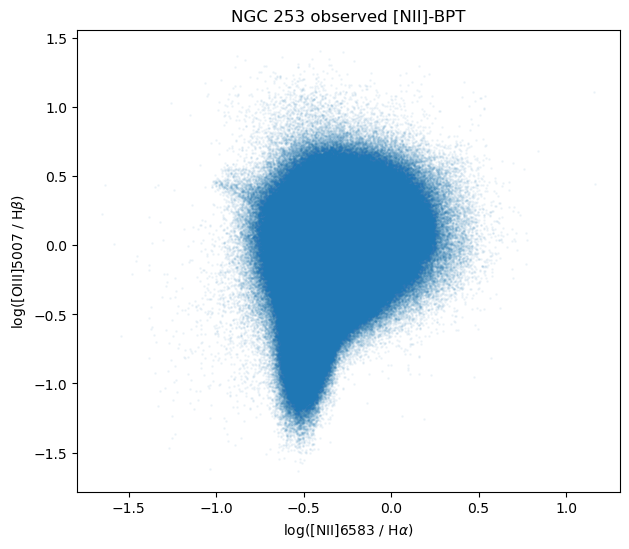

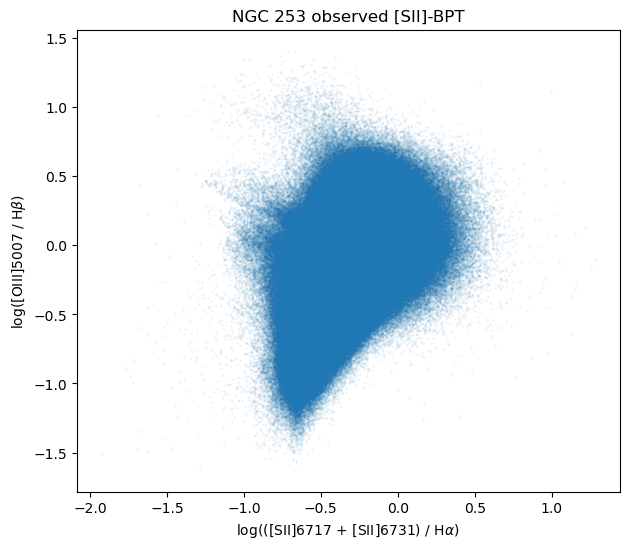

In [6]:
plt.figure(figsize=(7, 6))
plt.scatter(x_nii, y_oiii, s=1, alpha=0.05)
plt.xlabel(r"log([NII]6583 / H$\alpha$)")
plt.ylabel(r"log([OIII]5007 / H$\beta$)")
plt.title("NGC 253 observed [NII]-BPT")
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(x_sii, y_oiii, s=1, alpha=0.05)
plt.xlabel(r"log(([SII]6717 + [SII]6731) / H$\alpha$)")
plt.ylabel(r"log([OIII]5007 / H$\beta$)")
plt.title("NGC 253 observed [SII]-BPT")
plt.show()

In [7]:
class_order = ["PN", "DIG", "HII", "SNR"]
#models_bpt = pd.read_csv("models.csv")
models_bpt = pd.read_csv("models_constrained.csv")

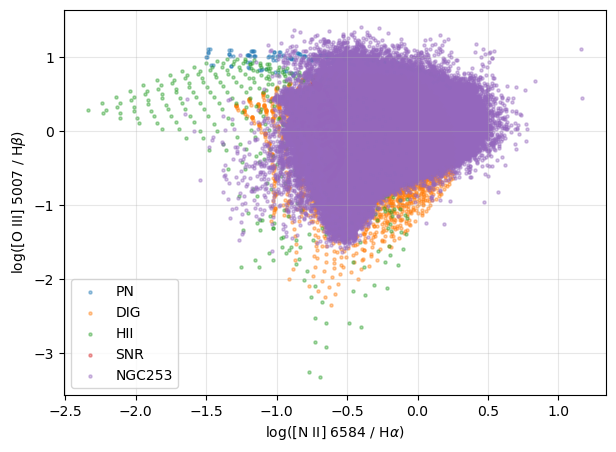

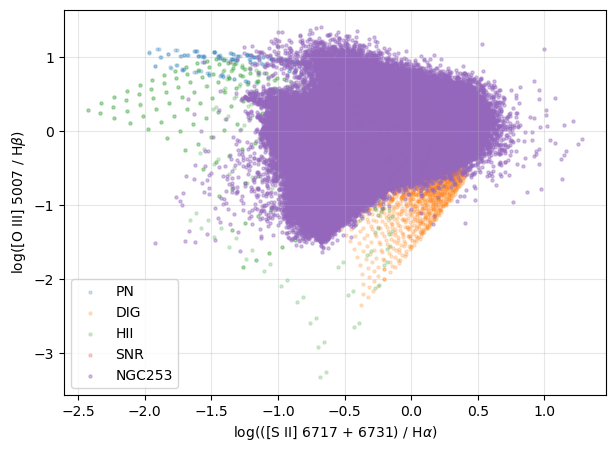

In [8]:
plt.figure(figsize=(7, 5))

for cls in class_order:
    sub = models_bpt[models_bpt["class"] == cls]
    plt.scatter(sub["log_NII_Ha"],sub["log_OIII_Hb"],s=5,alpha=0.4,label=cls)

plt.scatter(x_nii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log([N II] 6584 / H$\alpha$)")
plt.ylabel(r"log([O III] 5007 / H$\beta$)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 5))

for cls in class_order:
    sub = models_bpt[models_bpt["class"] == cls]
    plt.scatter(sub["log_SII_Ha"],sub["log_OIII_Hb"],s=5,alpha=0.2,label=cls)

plt.scatter(x_sii, y_oiii, label="NGC253", s=5, alpha=0.4)
plt.xlabel(r"log(([S II] 6717 + 6731) / H$\alpha$)")
plt.ylabel(r"log([O III] 5007 / H$\beta$)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()